# HA2 — Spatial concept network (construction stage)

This notebook completes the **network-construction stage** of Class 03 / HA2. The team's 40-sense dataset is the source pool. We select **15 distinct target senses** (7 Chinese, 8 English), then add ten explicitly defined category nodes: **25 concept nodes in total**. Chinese and English translations are not double-counted as separate concepts in this selection.

The parent–child edges below are **manual modelling proposals based on the fixed definitions in the final CSV**. They are not claimed to be verified WordNet/OpenHowNet hypernym edges. The notebook records source and confidence for each edge, keeps non-taxonomic relations out of the `IS-A` subgraph, validates the graph, and exports inspectable node and edge CSVs.

**Still to do for the full HA2:** independently review proposed parent relations; calculate and compare two S estimates; test multiple parents and missing edges; run the add-three/remove-three perturbation; write the 300-word interpretation and final limitations. No S score is calculated in this construction-stage notebook.

## 1. Select the 15 lexical concepts

The selection covers regions and boundaries, reference locations, intervals and nearness, routes, and geometric or bodily configuration. `concept_id` fixes the target sense, so polysemous word forms are not treated as unrestricted concepts.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import networkx as nx
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
data_dir = next((base / "data" for base in (current, *current.parents)
                 if (base / "data" / "spatial_relations.csv").is_file()), None)
if data_dir is None:
    raise FileNotFoundError("Open HA_2.ipynb in the project folder containing data/")

inventory = pd.read_csv(data_dir / "spatial_relations.csv", encoding="utf-8-sig")
selected_ids = ["ZH01", "ZH02", "ZH03", "ZH04", "ZH05", "ZH13", "ZH16",
                "EN04", "EN05", "EN06", "EN07", "EN08", "EN09", "EN11", "EN18"]
selected = inventory.set_index("concept_id").loc[selected_ids].reset_index()
assert len(selected) == 15 and selected.concept_id.is_unique
assert selected.language.value_counts().to_dict() == {"EN": 8, "ZH": 7}
display(selected[["concept_id", "language", "term", "part_of_speech",
                  "target_sense_definition_en", "category_parent"]])
print("Selected:", len(selected), "lexical senses from", data_dir / "spatial_relations.csv")

,concept_id,language,term,part_of_speech,target_sense_definition_en,category_parent
0,ZH01,ZH,位置,noun,A specified point or extent in a reference space.,spatial_location
1,ZH02,ZH,内部,noun,The region enclosed by a reference entity.,bounded_region_relation
2,ZH03,ZH,外部,locative_noun,A region beyond the boundary of a reference en...,bounded_region_relation
3,ZH04,ZH,边界,noun,A line delimiting the extent of an area.,spatial_limit
4,ZH05,ZH,中心,noun,A central point fixed by the limits of a refer...,reference_point_relation
5,ZH13,ZH,之间,relation,An intervening region bounded by two specified...,intervening_region_relation
6,ZH16,ZH,路径,noun,A route along which motion could occur.,route_or_traversal_relation
7,EN04,EN,proximity,noun,A short distance between entities relative to ...,spatial_interval_relation
8,EN05,EN,distance,noun,The measurable separation between two locations.,spatial_interval_relation
9,EN06,EN,gap,noun,An open interval or space between bounded enti...,spatial_interval_relation


Selected: 15 lexical senses from E:\Data Science\DS_2\7_Embodied AI and Neurocomputional Semantics\homework\data\spatial_relations.csv


## 2. Define category nodes and the `IS-A` rule

**Rule:** an edge `parent → child` receives type `IS-A` only if the fixed target sense of the child can reasonably be read as *a kind of* the parent category. For example, a center is a kind of reference location; a gap is a kind of spatial interval/opening. The categories are HA2 modelling definitions, not automatically inherited from the HA0 `category_parent` column. These judgements are recorded for team review.

The root is intentionally broad. Some leaves are three steps below it and some two steps below it; the later S calculation must use this stated graph and its chosen root.

In [2]:
category_specs = [
    ("CAT_ROOT", "spatial concept", "A concept concerning physical location, regions, extents, routes, spatial relations, or arrangement.", None, "spatial concept"),
    ("CAT_LOC", "locational concept", "A concept specifying a physical place, point, or region relative to a reference.", "CAT_ROOT", "location"),
    ("CAT_REGION", "relative region", "A spatial region specified with respect to one or more boundaries or reference entities.", "CAT_LOC", "region"),
    ("CAT_REF", "reference location", "A point or position determined in a reference space or figure.", "CAT_LOC", "reference point"),
    ("CAT_REL", "inter-entity relation", "A relation describing separation or immediate nearness between spatial references.", "CAT_ROOT", "spatial relation"),
    ("CAT_INTERVAL", "spatial interval", "An interval, opening, or degree of separation between spatial references.", "CAT_REL", "interval"),
    ("CAT_NEAR", "immediate nearness", "A relation of direct neighborhood or physical meeting between entities.", "CAT_REL", "nearness"),
    ("CAT_LIMIT", "spatial limit", "A line or surface delimiting a spatial region.", "CAT_ROOT", "limit"),
    ("CAT_ROUTE", "spatial route", "A route through space along which movement could occur.", "CAT_ROOT", "route"),
    ("CAT_FORM", "spatial structural property", "A geometric or bodily property of how parts, lines, or entities are arranged.", "CAT_ROOT", "structure"),
]
categories = pd.DataFrame(category_specs, columns=["node_id", "label", "definition_en", "parent_id", "graph_label"])
assert len(categories) == 10 and categories.node_id.is_unique

leaf_parent = {
    "ZH01": "CAT_REF", "ZH02": "CAT_REGION", "ZH03": "CAT_REGION",
    "ZH04": "CAT_LIMIT", "ZH05": "CAT_REF", "ZH13": "CAT_REGION",
    "ZH16": "CAT_ROUTE", "EN04": "CAT_INTERVAL", "EN05": "CAT_INTERVAL",
    "EN06": "CAT_INTERVAL", "EN07": "CAT_NEAR", "EN08": "CAT_FORM",
    "EN09": "CAT_FORM", "EN11": "CAT_FORM", "EN18": "CAT_NEAR",
}
leaf_graph_labels = {
    "ZH01": "position", "ZH02": "interior", "ZH03": "exterior",
    "ZH04": "boundary", "ZH05": "center", "ZH13": "between",
    "ZH16": "path", "EN04": "proximity", "EN05": "distance",
    "EN06": "gap", "EN07": "adjacency", "EN08": "alignment",
    "EN09": "angle", "EN11": "posture", "EN18": "contact",
}
assert set(leaf_parent) == set(selected.concept_id) == set(leaf_graph_labels)

category_nodes = pd.DataFrame({
    "node_id": categories.node_id, "label": categories.label,
    "graph_label": categories.graph_label, "node_type": "category",
    "language": "NA", "part_of_speech": "NA",
    "definition_en": categories.definition_en,
    "provenance": "manual_HA2_schema",
    "source_concept_id": "",
})
lexical_nodes = pd.DataFrame({
    "node_id": selected.concept_id,
    "label": selected.term,
    "graph_label": selected.concept_id + " " + selected.concept_id.map(leaf_graph_labels),
    "node_type": "lexical_sense",
    "language": selected.language,
    "part_of_speech": selected.part_of_speech,
    "definition_en": selected.target_sense_definition_en,
    "provenance": "spatial_relations.csv:target_sense_definition_en",
    "source_concept_id": selected.concept_id,
})
nodes = pd.concat([category_nodes, lexical_nodes], ignore_index=True)
assert len(nodes) == 25 and nodes.node_id.is_unique
display(nodes[["node_id", "label", "node_type", "definition_en", "provenance"]])
print("Nodes:", nodes.node_type.value_counts().to_dict())

,node_id,label,node_type,definition_en,provenance
0,CAT_ROOT,spatial concept,category,"A concept concerning physical location, region...",manual_HA2_schema
1,CAT_LOC,locational concept,category,"A concept specifying a physical place, point, ...",manual_HA2_schema
2,CAT_REGION,relative region,category,A spatial region specified with respect to one...,manual_HA2_schema
3,CAT_REF,reference location,category,A point or position determined in a reference ...,manual_HA2_schema
4,CAT_REL,inter-entity relation,category,A relation describing separation or immediate ...,manual_HA2_schema
5,CAT_INTERVAL,spatial interval,category,"An interval, opening, or degree of separation ...",manual_HA2_schema
6,CAT_NEAR,immediate nearness,category,A relation of direct neighborhood or physical ...,manual_HA2_schema
7,CAT_LIMIT,spatial limit,category,A line or surface delimiting a spatial region.,manual_HA2_schema
8,CAT_ROUTE,spatial route,category,A route through space along which movement cou...,manual_HA2_schema
9,CAT_FORM,spatial structural property,category,"A geometric or bodily property of how parts, l...",manual_HA2_schema


Nodes: {'lexical_sense': 15, 'category': 10}


## 3. Type and document every edge

The main taxonomy is a **manual proposal**, with parent → child direction throughout. Non-taxonomic edges use separate labels and are **excluded** from later depth and descendant calculations. `confidence` reflects confidence in this initial modelling decision; it is not an independently measured probability. Every edge has a provenance and an explanatory note.

The cross-links (`BOUNDS`, `BEYOND`, `CONNECTS`, `HAS_MEASURE`, `INVOLVES`) are type-level conceptual relations. They do not assert that a specific path, gap, or body in a corpus has those properties.

In [3]:
edge_records = []
def add_edge(source, target, edge_type, is_taxonomic, provenance, evidence, confidence):
    edge_records.append({
        "source": source, "target": target, "type": edge_type,
        "is_taxonomic": is_taxonomic, "provenance": provenance,
        "evidence_or_reason": evidence, "confidence": confidence,
        "review_status": "proposed_for_team_review",
    })

for row in categories.itertuples(index=False):
    if pd.notna(row.parent_id):
        add_edge(row.parent_id, row.node_id, "IS-A", True,
                 "manual_HA2_schema",
                 f"Category definition: {row.definition_en}", "medium")

lookup = selected.set_index("concept_id")
for concept_id, parent in leaf_parent.items():
    row = lookup.loc[concept_id]
    add_edge(parent, concept_id, "IS-A", True,
             f"manual_from_spatial_relations.csv:{concept_id}",
             f"Target sense: {row.target_sense_definition_en}; parent definition: "
             f"{categories.set_index('node_id').loc[parent, 'definition_en']}", "medium")

add_edge("ZH04", "ZH02", "BOUNDS", False,
         "manual_from_definitions:ZH04+ZH02",
         "The boundary delimits the enclosed internal region.", "medium")
add_edge("ZH03", "ZH04", "BEYOND", False,
         "manual_from_definitions:ZH03+ZH04",
         "The exterior target sense is a region beyond a reference boundary.", "high")
add_edge("ZH16", "ZH01", "CONNECTS", False,
         "manual_from_definitions:ZH16+ZH01",
         "A path is a route between positions; this relates concept types, not a particular route.", "medium")
add_edge("EN06", "EN05", "HAS_MEASURE", False,
         "manual_inference_from_definitions:EN06+EN05",
         "The width of a gap may be expressed as a distance.", "medium")
add_edge("EN11", "EN08", "INVOLVES", False,
         "manual_inference_from_definitions:EN11+EN08",
         "Bodily posture may involve the alignment of body parts.", "low")

edges = pd.DataFrame(edge_records)
assert len(edges) == 29 and edges[["source", "target", "type"]].duplicated().sum() == 0
assert not edges[["provenance", "evidence_or_reason", "confidence"]].isna().any().any()
assert edges.type.nunique() >= 3

taxonomy = nx.DiGraph()
taxonomy.add_nodes_from(nodes.node_id)
taxonomy.add_edges_from(edges.loc[edges.is_taxonomic, ["source", "target"]].itertuples(index=False, name=None))
assert nx.is_directed_acyclic_graph(taxonomy)
assert set(nx.descendants(taxonomy, "CAT_ROOT")) == set(nodes.node_id) - {"CAT_ROOT"}
assert taxonomy.in_degree("CAT_ROOT") == 0
assert all(taxonomy.in_degree(node) == 1 for node in nodes.node_id if node != "CAT_ROOT")
assert all(taxonomy.out_degree(node) == 0 for node in selected.concept_id)

network = nx.MultiDiGraph()
network.add_nodes_from((row.node_id, {"node_type": row.node_type, "label": row.label})
                       for row in nodes.itertuples(index=False))
network.add_edges_from((row.source, row.target,
                        {"type": row.type, "provenance": row.provenance,
                         "is_taxonomic": row.is_taxonomic})
                       for row in edges.itertuples(index=False))
assert network.number_of_nodes() == 25 and network.number_of_edges() == 29

depth = nx.single_source_shortest_path_length(taxonomy, "CAT_ROOT")
nodes["provisional_taxonomy_depth"] = nodes.node_id.map(depth)
nodes["parent_ids"] = nodes.node_id.map(lambda n: ";".join(taxonomy.predecessors(n)))
display(edges)
print("Edge types:", edges.type.value_counts().to_dict())
print("Taxonomy DAG:", nx.is_directed_acyclic_graph(taxonomy),
      "| all 25 nodes reachable from root:", len(depth) == 25)
print("Depth counts (raw only):", nodes.provisional_taxonomy_depth.value_counts().sort_index().to_dict())

,source,target,type,is_taxonomic,provenance,evidence_or_reason,confidence,review_status
0,CAT_ROOT,CAT_LOC,IS-A,True,manual_HA2_schema,Category definition: A concept specifying a ph...,medium,proposed_for_team_review
1,CAT_LOC,CAT_REGION,IS-A,True,manual_HA2_schema,Category definition: A spatial region specifie...,medium,proposed_for_team_review
2,CAT_LOC,CAT_REF,IS-A,True,manual_HA2_schema,Category definition: A point or position deter...,medium,proposed_for_team_review
3,CAT_ROOT,CAT_REL,IS-A,True,manual_HA2_schema,Category definition: A relation describing sep...,medium,proposed_for_team_review
4,CAT_REL,CAT_INTERVAL,IS-A,True,manual_HA2_schema,"Category definition: An interval, opening, or ...",medium,proposed_for_team_review
5,CAT_REL,CAT_NEAR,IS-A,True,manual_HA2_schema,Category definition: A relation of direct neig...,medium,proposed_for_team_review
6,CAT_ROOT,CAT_LIMIT,IS-A,True,manual_HA2_schema,Category definition: A line or surface delimit...,medium,proposed_for_team_review
7,CAT_ROOT,CAT_ROUTE,IS-A,True,manual_HA2_schema,Category definition: A route through space alo...,medium,proposed_for_team_review
8,CAT_ROOT,CAT_FORM,IS-A,True,manual_HA2_schema,Category definition: A geometric or bodily pro...,medium,proposed_for_team_review
9,CAT_REF,ZH01,IS-A,True,manual_from_spatial_relations.csv:ZH01,Target sense: A specified point or extent in a...,medium,proposed_for_team_review


Edge types: {'IS-A': 24, 'BOUNDS': 1, 'BEYOND': 1, 'CONNECTS': 1, 'HAS_MEASURE': 1, 'INVOLVES': 1}
Taxonomy DAG: True | all 25 nodes reachable from root: True
Depth counts (raw only): {0: 1, 1: 5, 2: 9, 3: 10}


## 4. Export the inspectable network data

The exported tables live beside the final source dataset in `data/`. `provisional_taxonomy_depth` describes this proposed graph only; it is **not** the verified external-resource `S_depth` in `spatial_relations.csv`. The later HA2 scoring stage will explicitly choose and normalize its own graph-derived S estimates.

In [4]:
node_path = data_dir / "ha2_nodes.csv"
edge_path = data_dir / "ha2_edges.csv"
nodes.to_csv(node_path, index=False, encoding="utf-8-sig")
edges.to_csv(edge_path, index=False, encoding="utf-8-sig")
print("Wrote", node_path.name, "and", edge_path.name,
      "with", len(nodes), "nodes and", len(edges), "typed edges")

Wrote ha2_nodes.csv and ha2_edges.csv with 25 nodes and 29 typed edges


## 5. Inspect the hierarchy and cross-links

The **left** panel shows only the proposed `IS-A` tree. The **right** panel shows the five non-taxonomic relations. Node IDs and complete definitions remain available in the exported tables. Arrows on the left point **parent → child**, matching the NetworkX hierarchy convention in Class 03. Arrows on the right follow each relation's `source → target` direction. No non-taxonomic edge contributes to taxonomic depth.

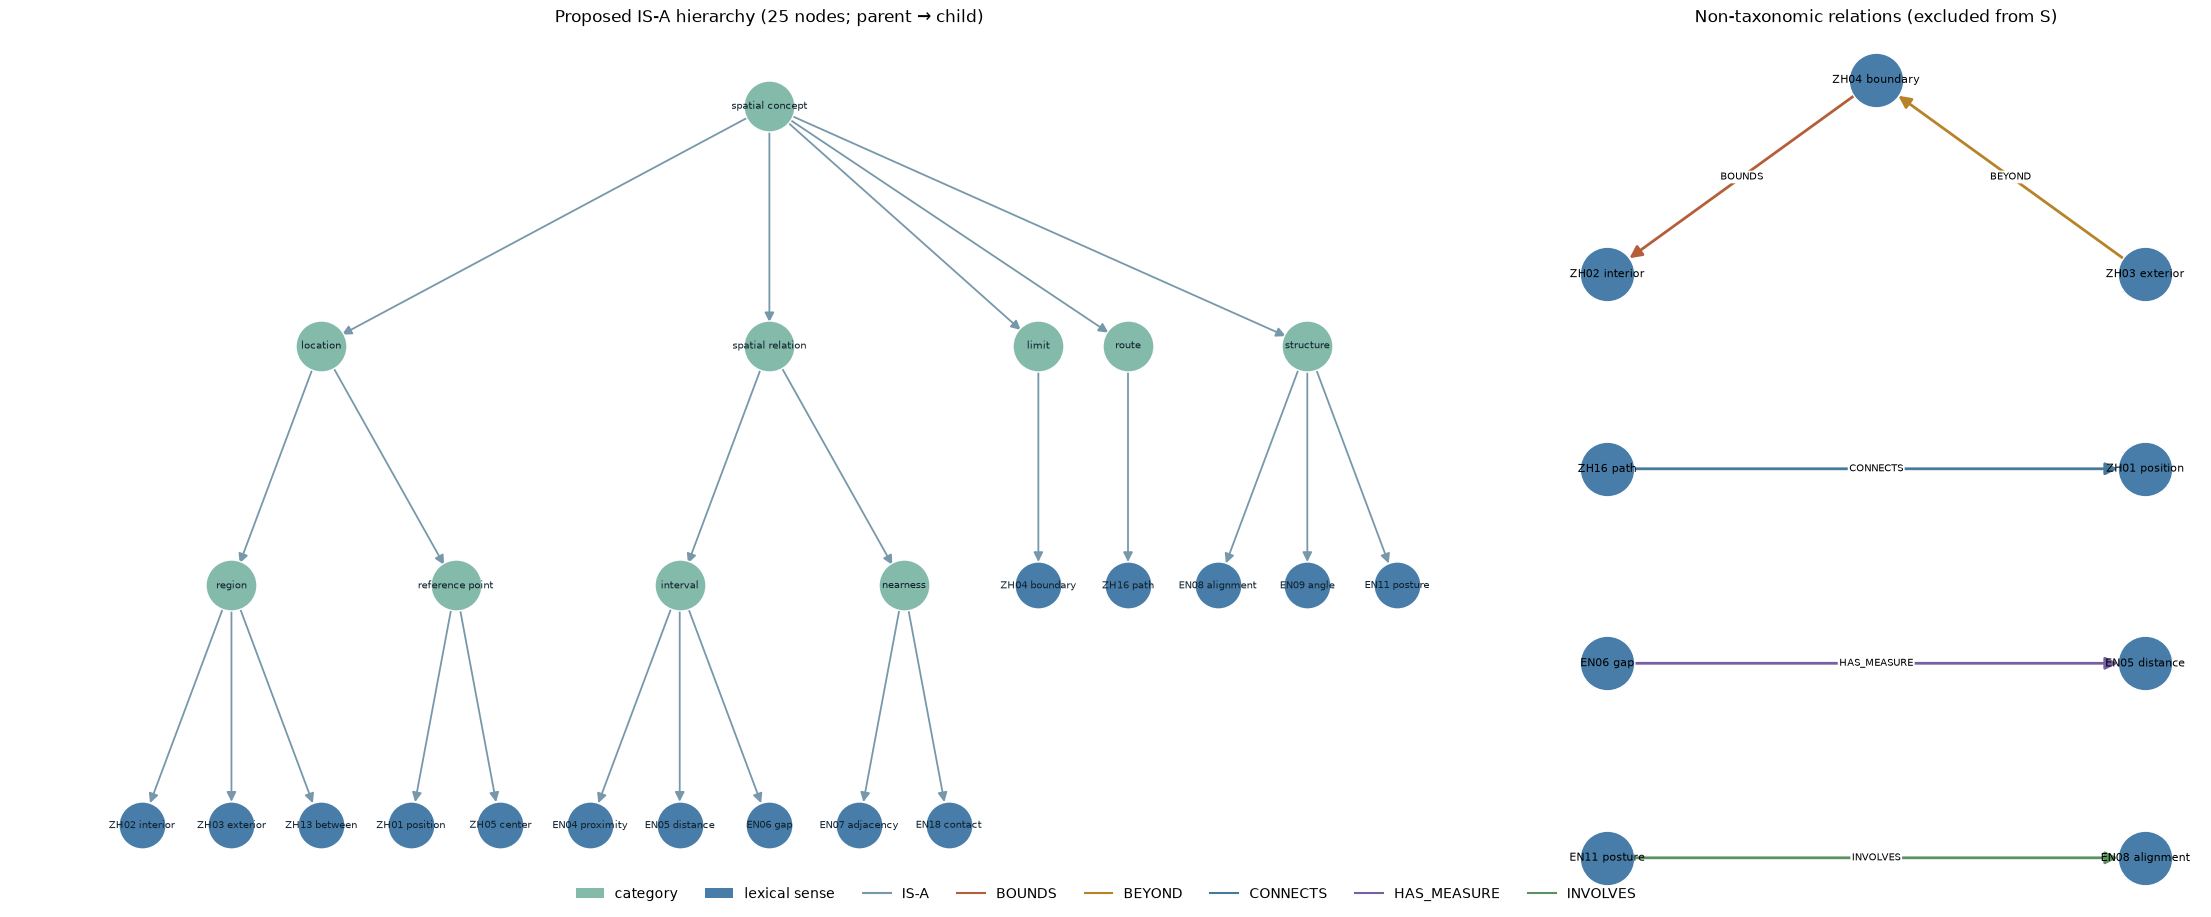

In [5]:
from collections import defaultdict

ordered_leaves = ["ZH02", "ZH03", "ZH13", "ZH01", "ZH05",
                  "EN04", "EN05", "EN06", "EN07", "EN18",
                  "ZH04", "ZH16", "EN08", "EN09", "EN11"]
leaf_x = {node: i for i, node in enumerate(ordered_leaves)}
def descendants_leaves(node):
    return [leaf for leaf in ordered_leaves
            if leaf == node or leaf in nx.descendants(taxonomy, node)]
pos = {node: (sum(leaf_x[x] for x in descendants_leaves(node)) /
              len(descendants_leaves(node)), -1.7 * depth[node])
       for node in nodes.node_id}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9),
                              gridspec_kw={"width_ratios": [3.5, 1.5]},
                              constrained_layout=True)
nx.draw_networkx_edges(taxonomy, pos, ax=ax1, arrows=True,
                       arrowstyle="-|>", arrowsize=14, width=1.3,
                       edge_color="#7798aa", node_size=1150)
for kind, color in [("category", "#83baa9"), ("lexical_sense", "#477da8")]:
    ids = nodes.loc[nodes.node_type == kind, "node_id"].tolist()
    nx.draw_networkx_nodes(taxonomy, pos, nodelist=ids, ax=ax1,
                           node_color=color, node_size=1350 if kind == "category" else 1150,
                           edgecolors="white", linewidths=1)
labels = nodes.set_index("node_id").graph_label.to_dict()
nx.draw_networkx_labels(taxonomy, pos, labels=labels, font_size=7,
                        font_color="#10212e", ax=ax1)
ax1.set_title("Proposed IS-A hierarchy (25 nodes; parent → child)")
ax1.axis("off")

other = edges.loc[~edges.is_taxonomic].copy()
relation_graph = nx.MultiDiGraph()
relation_graph.add_edges_from(other[["source", "target", "type"]].itertuples(index=False, name=None))
relation_pos = {
    "ZH04": (0, 2), "ZH02": (-1, 1), "ZH03": (1, 1),
    "ZH16": (-1, 0), "ZH01": (1, 0),
    "EN06": (-1, -1), "EN05": (1, -1),
    "EN11": (-1, -2), "EN08": (1, -2),
}
assert set(relation_graph.nodes) == set(relation_pos)
relation_colors = {
    "BOUNDS": "#b45f39", "BEYOND": "#b78328", "CONNECTS": "#467a9b",
    "HAS_MEASURE": "#7660a4", "INVOLVES": "#5c9162",
}
for row in other.itertuples(index=False):
    nx.draw_networkx_edges(relation_graph, relation_pos,
                           edgelist=[(row.source, row.target)], ax=ax2,
                           edge_color=relation_colors[row.type], width=2,
                           arrows=True, arrowsize=18, node_size=1550)
nx.draw_networkx_nodes(relation_graph, relation_pos, ax=ax2,
                       node_color="#477da8", node_size=1550,
                       edgecolors="white", linewidths=1)
nx.draw_networkx_labels(relation_graph, relation_pos,
                        labels={node: labels[node] for node in relation_graph.nodes},
                        ax=ax2, font_size=8)
nx.draw_networkx_edge_labels(relation_graph, relation_pos,
                             edge_labels={(row.source, row.target): row.type
                                          for row in other.itertuples(index=False)},
                             ax=ax2, font_size=7, rotate=False,
                             bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none"})
ax2.set_title("Non-taxonomic relations (excluded from S)")
ax2.axis("off")

legend = [Patch(facecolor="#83baa9", label="category"),
          Patch(facecolor="#477da8", label="lexical sense"),
          Line2D([0], [0], color="#7798aa", label="IS-A")]
legend += [Line2D([0], [0], color=color, label=name)
           for name, color in relation_colors.items()]
fig.legend(handles=legend, loc="lower center", ncol=8, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
display(fig)
plt.close(fig)

## 6. Construction-stage audit and handoff

- **Coverage:** 15 fixed lexical senses (7 ZH, 8 EN), ten manual category nodes, one root, 24 proposed `IS-A` edges, and five labelled non-taxonomic edges.
- **Graph checks:** all 25 nodes exist, every node is reachable from the chosen root in the taxonomic subgraph, and that subgraph has no cycles. The graph currently gives each non-root concept one parent; multiple inheritance remains a later experiment.
- **Provenance limit:** `manual_from_spatial_relations.csv` means an analyst classified the fixed definition. It does not mean a lexical resource explicitly supplied that edge. Lower-confidence cross-links deserve team review before final submission.
- **Next HA2 step:** review each parent–child decision; then add depth-based and breadth-aware S with explicit normalization, at least three broad/narrow comparisons, a second-parent/missing-edge test, and the specified add-three/remove-three perturbation.